In [1]:
import cv2 as cv
from IPython.display import display, clear_output
import PIL.Image

face and eyes detection:

In [2]:
# haarcascades_path = '/usr/share/opencv4/haarcascades/'

face_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_alt.xml')
eyes_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_eye_tree_eyeglasses.xml')
assert not face_cascade.empty(), 'face cascade nie wczytany'
assert not eyes_cascade.empty(), 'eyes cascade nie wczytany'

def f(frame):
    gray = cv.equalizeHist(cv.cvtColor(frame, cv.COLOR_BGR2GRAY))
    for (x, y, w, h) in face_cascade.detectMultiScale(gray):
        cv.rectangle(frame, (x, y), (x + w, y + h), (255, 0, 255), 4)
        roi = gray[y:y + h, x:x + w]
        for (xe, ye, we, he) in eyes_cascade.detectMultiScale(roi):
            cv.rectangle(frame, (x + xe, y + ye), (x + xe + we, y + ye + he), (255, 0, 255), 4)
    return frame


camera setup:

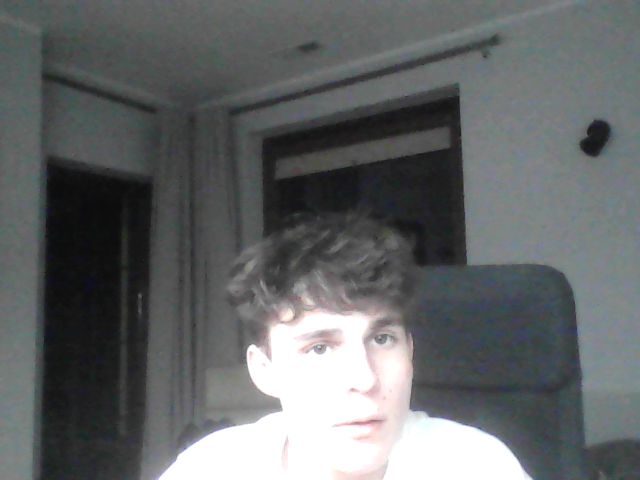

In [3]:
#camera.
cap = cv.VideoCapture(0, cv.CAP_V4L2)
if not cap.isOpened():
    raise RuntimeError('camera error')

try:
    while True:
        ret, frame = cap.read()
        if not ret or frame is None:
            print('error')
            break
        frame = f(frame)
        clear_output(wait=True)
        display(PIL.Image.fromarray(cv.cvtColor(frame, cv.COLOR_BGR2RGB)))
except KeyboardInterrupt:
    pass
finally:
    cap.release()